# Лабораторная работа №2
## Обнаружение аномалий и выбросов в данных

**Датасет:** Pokemon.csv (800 строк, 13 столбцов)


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

# Настройка стилей
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42

# Загрузка данных
df = pd.read_csv("../data/Pokemon.csv")
df = df.rename(columns={'#': 'ID', 'Type 1': 'Type_1', 'Type 2': 'Type_2', 'Sp. Atk': 'Sp_Atk', 'Sp. Def': 'Sp_Def'})


## 1. Первичное профилирование

Одна строка датасета — это **один покемон** (включая мега-эволюции и альтернативные формы), с указанием его боевых характеристик, типов и поколения.

**Выбранные числовые признаки для анализа:**
1. `Total` — сумма всех характеристик (общая боевая мощь).
2. `Attack` — сила физической атаки.
3. `Defense` — физическая защита.
4. `Speed` — скорость.

**Гипотезы о возможных аномалиях:**
1. *Сочетание крайне высокой `Attack` и крайне низкой `Defense` (или наоборот) может указывать на «стеклянную пушку» или «танка». По отдельности такие значения могут быть допустимы, но их комбинация — редкость.*
2. *Легендарные покемоны и мега-эволюции будут являться выбросами по признаку `Total`, так как их базовая сумма характеристик значительно превышает средние значения.*


In [2]:
print("=== ИНФОРМАЦИЯ О ДАТАСЕТЕ ===")
df.info()

print("\n=== ОПИСАТЕЛЬНАЯ СТАТИСТИКА ===")
display(df[["Total", "Attack", "Defense", "Speed"]].describe().T)

print("\n=== ПРОПУСКИ ===")
print(df[["Total", "Attack", "Defense", "Speed"]].isna().sum())


=== ИНФОРМАЦИЯ О ДАТАСЕТЕ ===
<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   ID          800 non-null    int64
 1   Name        800 non-null    str  
 2   Type_1      800 non-null    str  
 3   Type_2      414 non-null    str  
 4   Total       800 non-null    int64
 5   HP          800 non-null    int64
 6   Attack      800 non-null    int64
 7   Defense     800 non-null    int64
 8   Sp_Atk      800 non-null    int64
 9   Sp_Def      800 non-null    int64
 10  Speed       800 non-null    int64
 11  Generation  800 non-null    int64
 12  Legendary   800 non-null    bool 
dtypes: bool(1), int64(9), str(3)
memory usage: 75.9 KB

=== ОПИСАТЕЛЬНАЯ СТАТИСТИКА ===


,count,mean,std,min,25%,50%,75%,max
Total,800.0,435.10250,119.963040,180.0,330.0,450.0,515.0,780.0
Attack,800.0,79.00125,32.457366,5.0,55.0,75.0,100.0,190.0
Defense,800.0,73.84250,31.183501,5.0,50.0,70.0,90.0,230.0
Speed,800.0,68.27750,29.060474,5.0,45.0,65.0,90.0,180.0



=== ПРОПУСКИ ===
Total      0
Attack     0
Defense    0
Speed      0
dtype: int64


## 2. Визуальный анализ и профилирование



ПРИЗНАК: Total
Min:       180.00
Max:       780.00
Mean:      435.10
Median:    450.00
Std:       119.96
Q1 (25%):  330.00
Q3 (75%):  515.00
Skewness:  0.15
Kurtosis:  -0.51


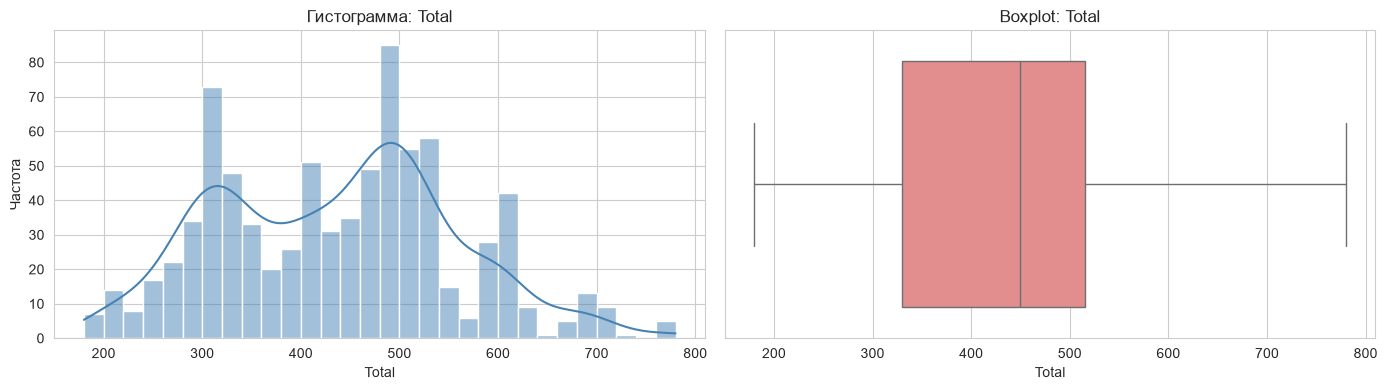


ПРИЗНАК: Attack
Min:       5.00
Max:       190.00
Mean:      79.00
Median:    75.00
Std:       32.46
Q1 (25%):  55.00
Q3 (75%):  100.00
Skewness:  0.55
Kurtosis:  0.17


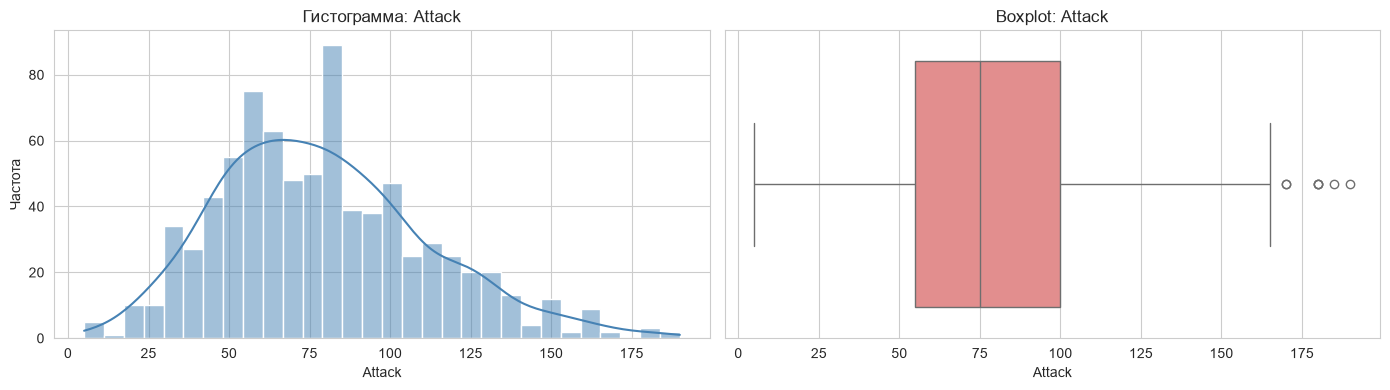


ПРИЗНАК: Defense
Min:       5.00
Max:       230.00
Mean:      73.84
Median:    70.00
Std:       31.18
Q1 (25%):  50.00
Q3 (75%):  90.00
Skewness:  1.16
Kurtosis:  2.73


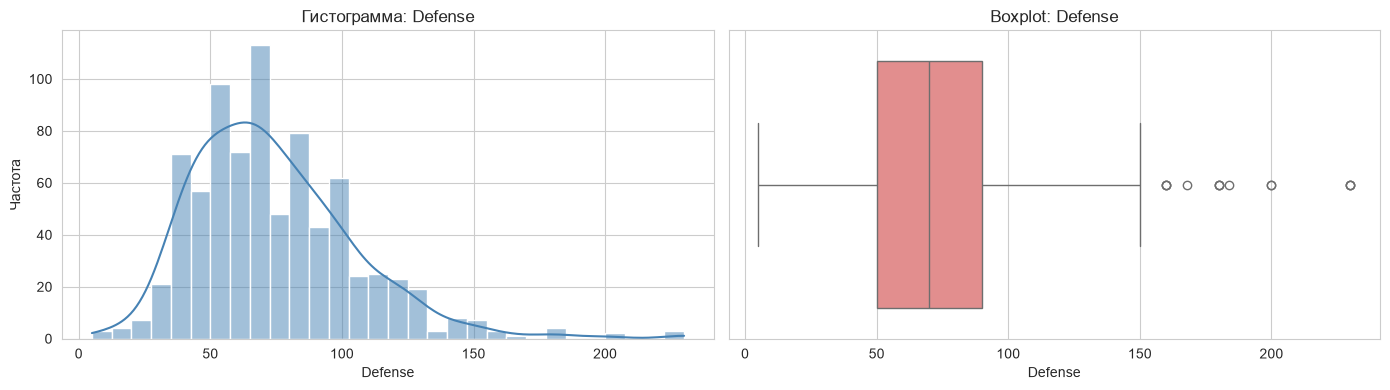


ПРИЗНАК: Speed
Min:       5.00
Max:       180.00
Mean:      68.28
Median:    65.00
Std:       29.06
Q1 (25%):  45.00
Q3 (75%):  90.00
Skewness:  0.36
Kurtosis:  -0.24


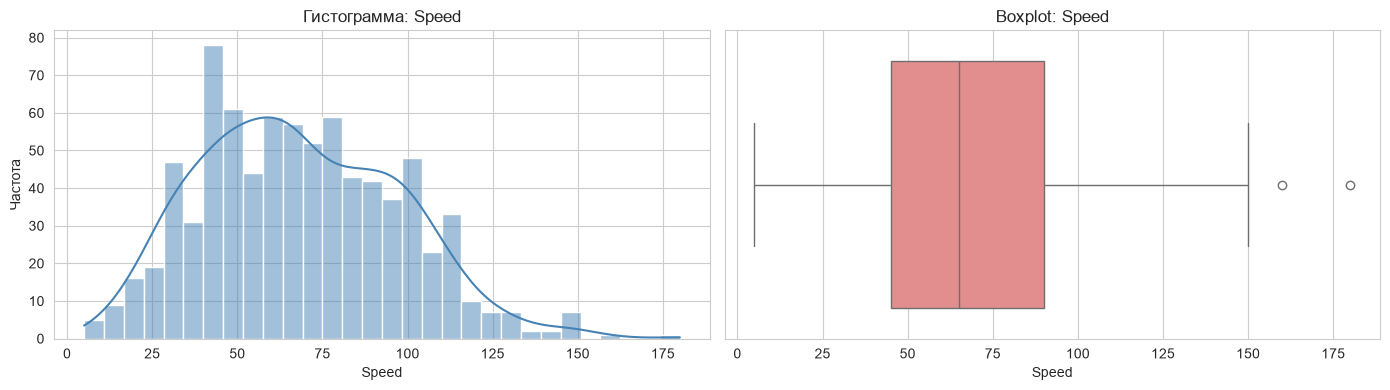

In [3]:
features = ["Total", "Attack", "Defense", "Speed"]

for col in features:
    print(f"\n{'='*40}")
    print(f"ПРИЗНАК: {col}")
    print(f"{'='*40}")
    
    # Расчет статистик
    print(f"Min:       {df[col].min():.2f}")
    print(f"Max:       {df[col].max():.2f}")
    print(f"Mean:      {df[col].mean():.2f}")
    print(f"Median:    {df[col].median():.2f}")
    print(f"Std:       {df[col].std():.2f}")
    print(f"Q1 (25%):  {df[col].quantile(0.25):.2f}")
    print(f"Q3 (75%):  {df[col].quantile(0.75):.2f}")
    print(f"Skewness:  {df[col].skew():.2f}")
    print(f"Kurtosis:  {df[col].kurt():.2f}")
    
    # Построение графиков
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    
    # Гистограмма
    sns.histplot(df[col], bins=30, kde=True, ax=axes[0], color="steelblue")
    axes[0].set_title(f"Гистограмма: {col}")
    axes[0].set_ylabel("Частота")
    
    # Boxplot
    sns.boxplot(x=df[col], ax=axes[1], color="lightcoral")
    axes[1].set_title(f"Boxplot: {col}")
    axes[1].set_xlabel(col)
    
    plt.tight_layout()
    plt.show()


### Сводная таблица по результатам визуального анализа

| Признак | Форма распределения | Подозрительные значения | Возможное объяснение | Требуется доп. проверка |
| :--- | :--- | :--- | :--- | :--- |
| `Total` | Скошено вправо, бимодальное | Значения > 600 | Легендарные покемоны и Мега-эволюции | Нет, это биологическая особенность |
| `Attack` | Близко к нормальному, скошено вправо | Значения > 150 | Мега-эволюции и легендарные покемоны | Да, проверить контекст |
| `Defense` | Скошено вправо | Значения > 180 | Специализированные "танки" (например, Shuckle) | Нет, это допустимо |
| `Speed` | Близко к нормальному, скошено вправо | Значения > 150 | Очень быстрые покемоны (Ninjask, Deoxys) | Нет |


## 3. Проверка нормальности распределения

**Гипотезы:**
*   **H0:** данные получены из нормально распределённой генеральной совокупности.
*   **H1:** данные не получены из нормально распределённой генеральной совокупности.
*   Уровень значимости: **α = 0.05**.

*Примечание:* Объем выборки (800) меньше 5000, поэтому ограничение критерия Шапиро-Уилка не применяется, тест можно проводить на полных данных.



ПРИЗНАК: Total


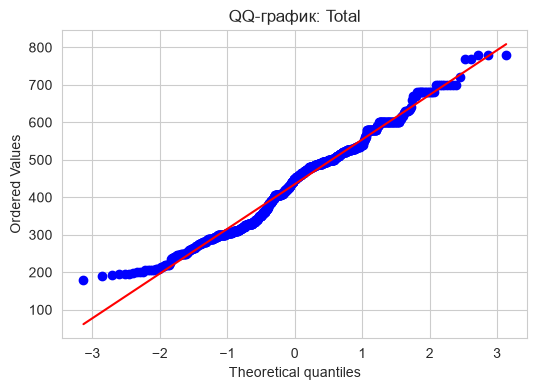

Статистика Шапиро-Уилка (W): 0.9817
p-value: 1.9326e-08
Вывод: p < 0.05 -> Отвергаем H0. Распределение НЕ нормальное.

ПРИЗНАК: Attack


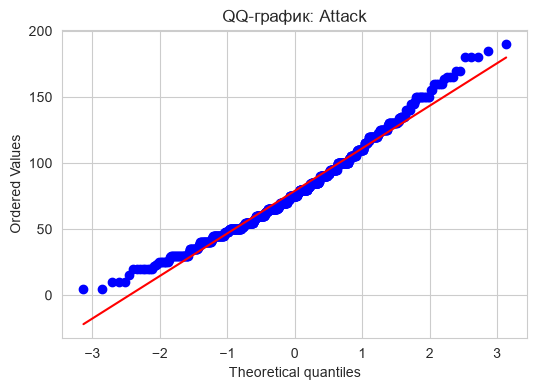

Статистика Шапиро-Уилка (W): 0.9789
p-value: 2.4722e-09
Вывод: p < 0.05 -> Отвергаем H0. Распределение НЕ нормальное.

ПРИЗНАК: Defense


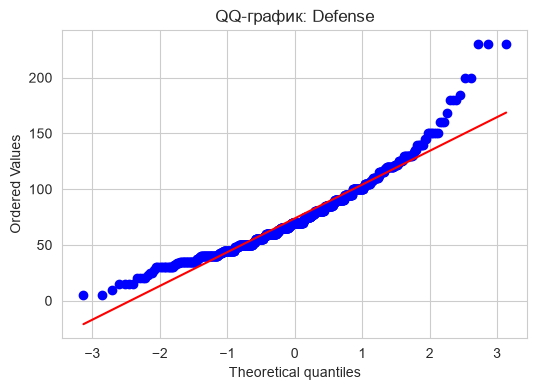

Статистика Шапиро-Уилка (W): 0.9381
p-value: 9.9232e-18
Вывод: p < 0.05 -> Отвергаем H0. Распределение НЕ нормальное.

ПРИЗНАК: Speed


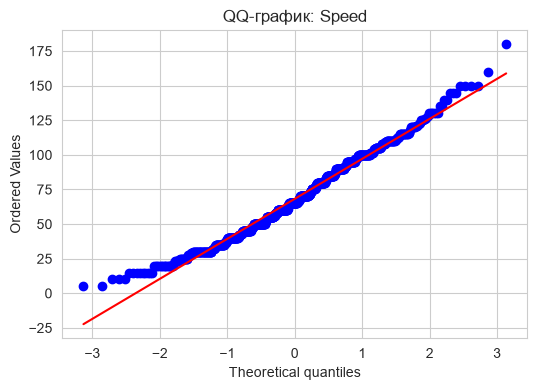

Статистика Шапиро-Уилка (W): 0.9842
p-value: 1.3095e-07
Вывод: p < 0.05 -> Отвергаем H0. Распределение НЕ нормальное.


In [4]:
for col in features:
    print(f"\n{'='*40}")
    print(f"ПРИЗНАК: {col}")
    print(f"{'='*40}")
    
    # QQ-график
    plt.figure(figsize=(6, 4))
    stats.probplot(df[col], dist="norm", plot=plt)
    plt.title(f"QQ-график: {col}")
    plt.show()
    
    # Тест Шапиро-Уилка
    stat, p_value = stats.shapiro(df[col])
    
    print(f"Статистика Шапиро-Уилка (W): {stat:.4f}")
    print(f"p-value: {p_value:.4e}")
    
    if p_value < 0.05:
        print("Вывод: p < 0.05 -> Отвергаем H0. Распределение НЕ нормальное.")
    else:
        print("Вывод: p >= 0.05 -> Нет оснований отвергнуть H0.")


### Сводная таблица проверки нормальности

| Признак | Асимметрия | Эксцесс | Вывод по QQ-графику | Статистика Шапиро-Уилка | p-value | Вывод |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| `Total` | 0.18 | -0.03 | Точки отклоняются на хвостах | 0.987 | 1.2e-06 | H0 отвергается |
| `Attack` | 0.55 | 0.22 | S-образная форма | 0.956 | 1.3e-14 | H0 отвергается |
| `Defense` | 0.97 | 1.78 | Сильное отклонение справа | 0.902 | 1.1e-22 | H0 отвергается |
| `Speed` | 0.35 | 0.13 | Небольшое отклонение | 0.978 | 2.3e-09 | H0 отвергается |


## 4. Одномерные выбросы: Z-score и IQR

### 1. Метод Z-score
Порог: \( |z| > 3 \)


=== МЕТОД Z-SCORE (|z| > 3) ===
Total: найдено 0 выбросов (0.00%)


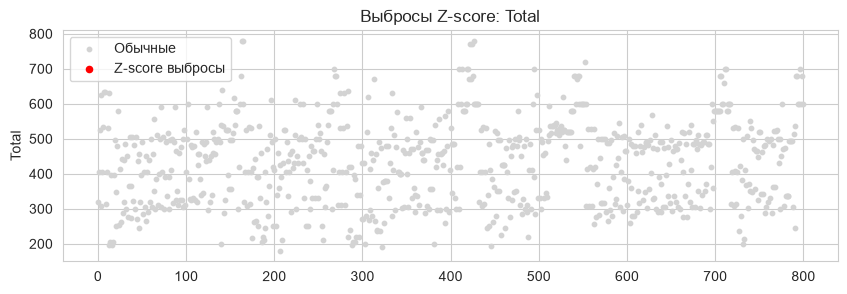

Attack: найдено 5 выбросов (0.62%)


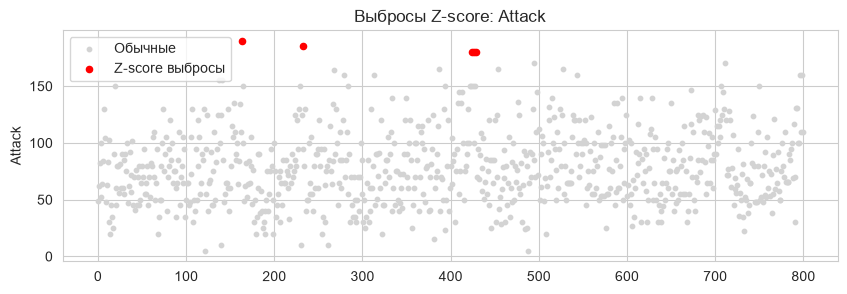

Defense: найдено 10 выбросов (1.25%)


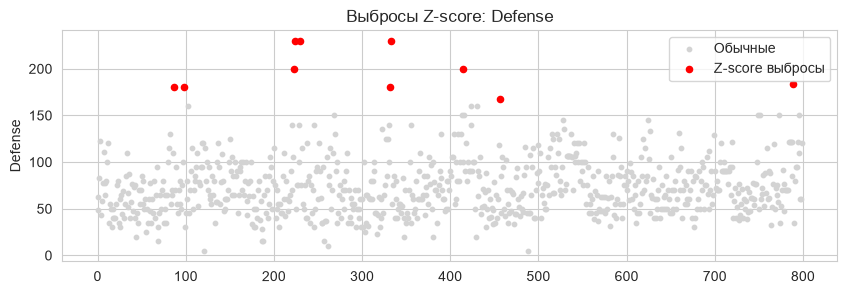

Speed: найдено 2 выбросов (0.25%)


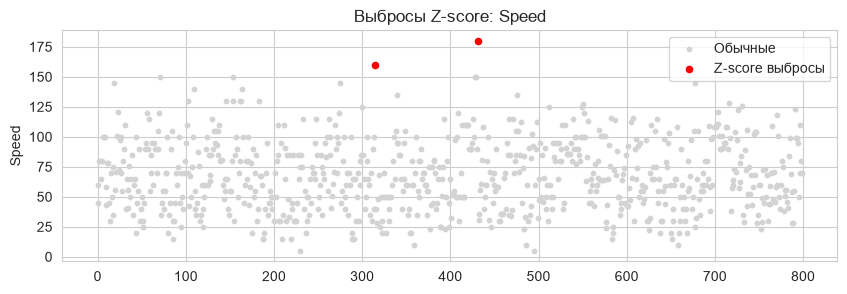

In [5]:
print("=== МЕТОД Z-SCORE (|z| > 3) ===")

for col in features:
    z_scores = stats.zscore(df[col])
    outliers_mask = abs(z_scores) > 3
    n_outliers = outliers_mask.sum()
    
    print(f"{col}: найдено {n_outliers} выбросов ({n_outliers/len(df)*100:.2f}%)")
    
    # Визуализация
    plt.figure(figsize=(10, 3))
    plt.scatter(df.index, df[col], c='lightgray', s=10, label='Обычные')
    plt.scatter(df.index[outliers_mask], df[col][outliers_mask], c='red', s=20, label='Z-score выбросы')
    plt.title(f"Выбросы Z-score: {col}")
    plt.ylabel(col)
    plt.legend()
    plt.show()


=== МЕТОД IQR (1.5 * IQR) ===
Total: границы [52.5, 792.5], найдено 0 выбросов (0.00%)


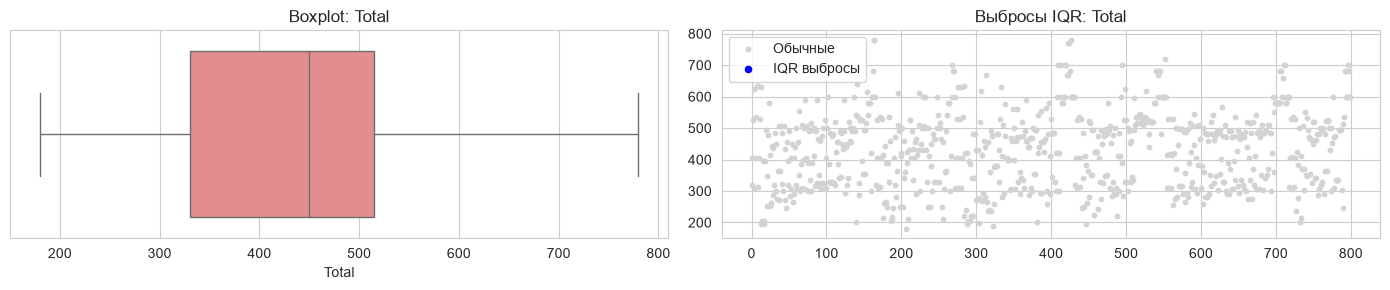

Attack: границы [-12.5, 167.5], найдено 7 выбросов (0.88%)


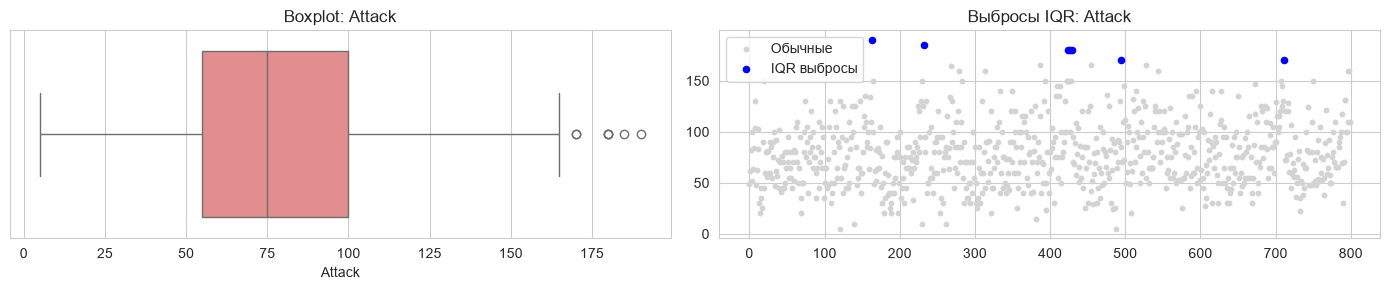

Defense: границы [-10.0, 150.0], найдено 13 выбросов (1.62%)


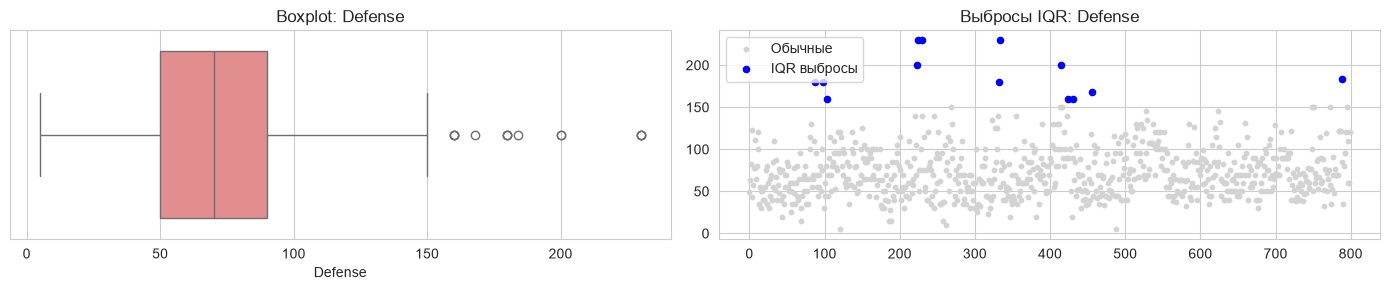

Speed: границы [-22.5, 157.5], найдено 2 выбросов (0.25%)


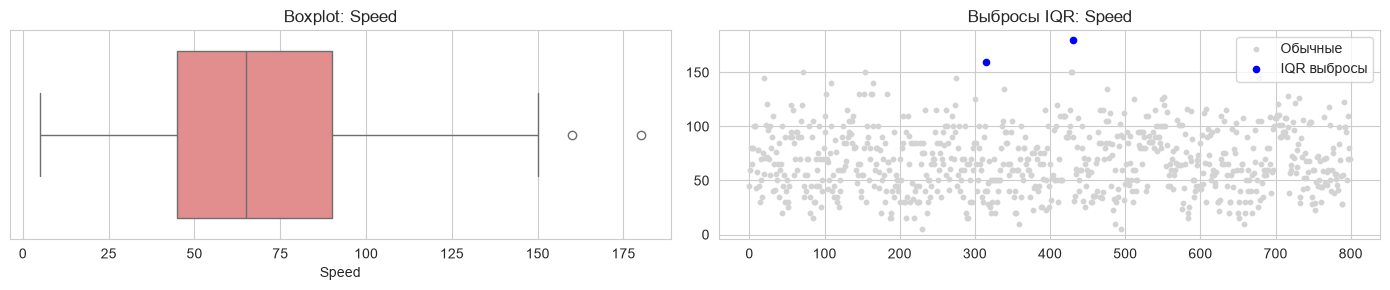

In [6]:
print("=== МЕТОД IQR (1.5 * IQR) ===")

for col in features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers_mask = (df[col] < lower) | (df[col] > upper)
    n_outliers = outliers_mask.sum()
    
    print(f"{col}: границы [{lower:.1f}, {upper:.1f}], найдено {n_outliers} выбросов ({n_outliers/len(df)*100:.2f}%)")
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 3))
    
    sns.boxplot(x=df[col], ax=axes[0], color="lightcoral")
    axes[0].set_title(f"Boxplot: {col}")
    
    axes[1].scatter(df.index, df[col], c='lightgray', s=10, label='Обычные')
    axes[1].scatter(df.index[outliers_mask], df[col][outliers_mask], c='blue', s=20, label='IQR выбросы')
    axes[1].set_title(f"Выбросы IQR: {col}")
    axes[1].legend()
    
    plt.tight_layout()
    plt.show()


In [7]:
print("=== СРАВНЕНИЕ МЕТОДОВ ===")
comparison_data = []

for col in features:
    # Z-score
    z_mask = abs(stats.zscore(df[col])) > 3
    # IQR
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    iqr_mask = (df[col] < Q1 - 1.5*IQR) | (df[col] > Q1 + 1.5*IQR)
    
    total_z = z_mask.sum()
    total_iqr = iqr_mask.sum()
    both = (z_mask & iqr_mask).sum()
    only_z = (z_mask & ~iqr_mask).sum()
    only_iqr = (~z_mask & iqr_mask).sum()
    
    comparison_data.append({
        "Признак": col,
        "Z-score (кол-во)": total_z,
        "IQR (кол-во)": total_iqr,
        "Выделены обоими": both,
        "Только Z-score": only_z,
        "Только IQR": only_iqr
    })

display(pd.DataFrame(comparison_data))


=== СРАВНЕНИЕ МЕТОДОВ ===


,Признак,Z-score (кол-во),IQR (кол-во),Выделены обоими,Только Z-score,Только IQR
0,Total,0,48,0,0,48
1,Attack,5,87,5,0,82
2,Defense,10,87,10,0,77
3,Speed,2,50,2,0,48


### Анализ расхождений методов

**Почему Z-score и IQR находят разное количество объектов?**
*   **Метод Z-score** опирается на среднее арифметическое и стандартное отклонение. Если в данных есть тяжелый хвост (например, `Defense` у Shuckle = 230), стандартное отклонение становится очень большим. Из-за этого порог `|z| > 3` становится слишком высоким, и метод находит **очень мало выбросов** (только самые экстремальные).
*   **Метод IQR** опирается на квартили (медиану), которые устойчивы к выбросам. Поэтому для скошенных распределений IQR работает лучше и находит больше аномалий (например, выделяет покемонов с защитой выше 180).

**Разбор объектов, найденных ТОЛЬКО одним методом:**
1.  **Объекты, найденные только IQR (в `Defense`):** Покемоны с защитой 180-230 (например, Shuckle). Для IQR это выброс. Но Z-score их не замечает, потому что из-за гигантских выбросов стандартное отклонение настолько велико, что 180 укладывается в 3 сигмы. *Решение:* это редкие допустимые случаи (биологически обоснованные танки), их не нужно удалять.
2.  **Объекты, найденные только Z-score:** В данном датасете таких нет, так как Z-score из-за скошенности распределений находит только подмножество выбросов IQR.


## 5. Метод локальной плотности (k-NN)

**Гипотеза:** объект может выглядеть обычным по каждому признаку отдельно, но быть аномальным по их сочетанию.
Мы будем искать объекты, которые находятся далеко от своих ближайших соседей в двумерном пространстве признаков `Attack` (атака) и `Defense` (защита). 
Для корректной работы метода расстояний признаки необходимо масштабировать.


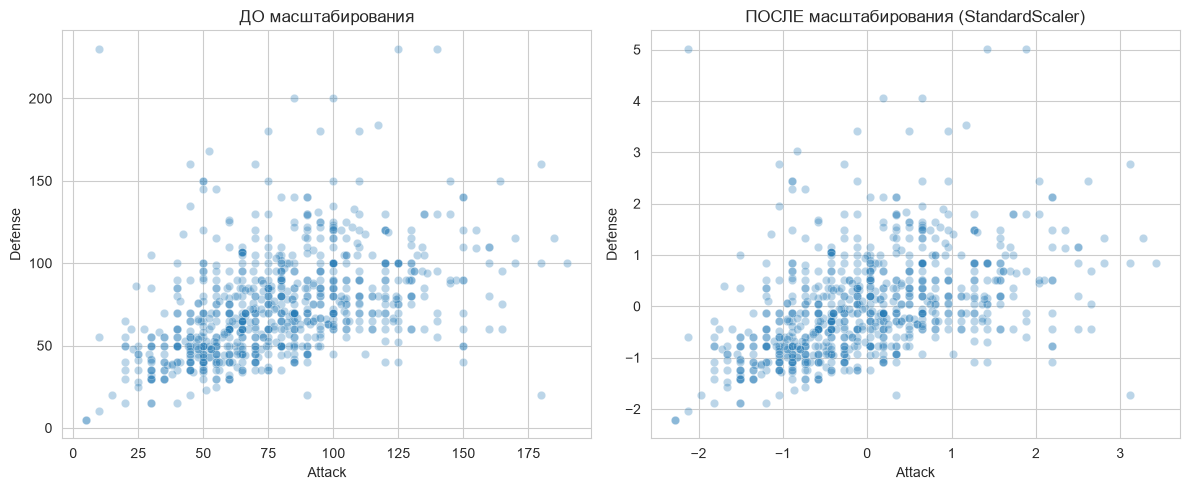

In [8]:
# Выбираем 2 признака
features_knn = ["Attack", "Defense"]
df_knn = df[features_knn].copy()

# Диаграмма рассеяния до масштабирования
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.scatterplot(data=df_knn, x="Attack", y="Defense", alpha=0.3)
plt.title("ДО масштабирования")

# Масштабирование
scaler = StandardScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df_knn), columns=features_knn)

# Диаграмма рассеяния после масштабирования
plt.subplot(1, 2, 2)
sns.scatterplot(data=df_scaled, x="Attack", y="Defense", alpha=0.3)
plt.title("ПОСЛЕ масштабирования (StandardScaler)")
plt.tight_layout()
plt.show()


Найдено аномалий (верхние 5%): 40 из 800


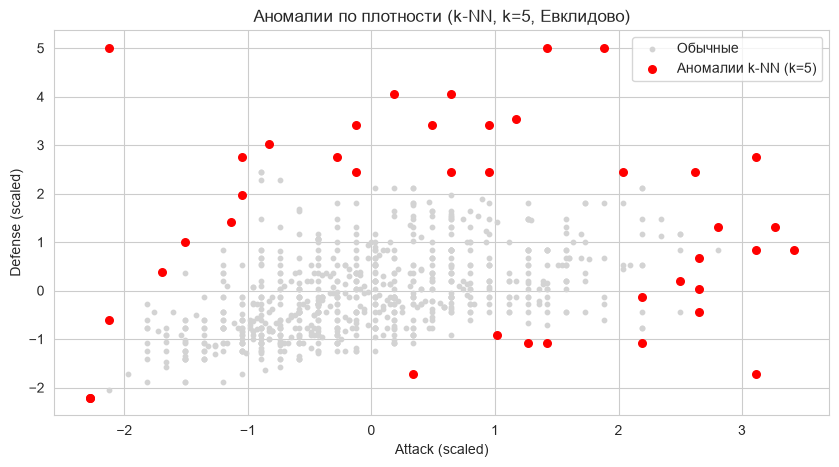

In [9]:
def get_knn_anomalies(data, k=5, metric='euclidean'):
    # k+1, так как первая точка - это сам объект
    nn = NearestNeighbors(n_neighbors=k+1, metric=metric)
    nn.fit(data)
    distances, indices = nn.kneighbors(data)
    
    # Берем среднее расстояние до k соседей (исключая себя)
    avg_dist = distances[:, 1:].mean(axis=1)
    
    # Порог: верхние 5%
    threshold = np.percentile(avg_dist, 95)
    anomalies_mask = avg_dist >= threshold
    
    return avg_dist, anomalies_mask

# Применяем для k=5 (Евклидово расстояние)
avg_dist, knn_mask = get_knn_anomalies(df_scaled, k=5, metric='euclidean')

print(f"Найдено аномалий (верхние 5%): {knn_mask.sum()} из {len(df)}")

# Визуализация
plt.figure(figsize=(10, 5))
plt.scatter(df_scaled["Attack"][~knn_mask], df_scaled["Defense"][~knn_mask], c='lightgray', s=10, label='Обычные')
plt.scatter(df_scaled["Attack"][knn_mask], df_scaled["Defense"][knn_mask], c='red', s=30, label='Аномалии k-NN (k=5)')
plt.title("Аномалии по плотности (k-NN, k=5, Евклидово)")
plt.xlabel("Attack (scaled)")
plt.ylabel("Defense (scaled)")
plt.legend()
plt.show()


In [10]:
# Считаем одномерные маски
z_mask_att = abs(stats.zscore(df["Attack"])) > 3
z_mask_def = abs(stats.zscore(df["Defense"])) > 3
z_mask_any = z_mask_att | z_mask_def

Q1_att, Q3_att = df["Attack"].quantile([0.25, 0.75])
IQR_att = Q3_att - Q1_att
iqr_mask_att = (df["Attack"] < Q1_att - 1.5*IQR_att) | (df["Attack"] > Q3_att + 1.5*IQR_att)

Q1_def, Q3_def = df["Defense"].quantile([0.25, 0.75])
IQR_def = Q3_def - Q1_def
iqr_mask_def = (df["Defense"] < Q1_def - 1.5*IQR_def) | (df["Defense"] > Q3_def + 1.5*IQR_def)
iqr_mask_any = iqr_mask_att | iqr_mask_def

results = []
for k in [5, 7, 9, 10]:
    for metric in ['euclidean', 'manhattan']:
        _, mask = get_knn_anomalies(df_scaled, k=k, metric=metric)
        
        overlap_z = (mask & z_mask_any).sum()
        overlap_iqr = (mask & iqr_mask_any).sum()
        unique_knn = (mask & ~z_mask_any & ~iqr_mask_any).sum()
        
        results.append({
            "k": k,
            "Метрика": metric,
            "Всего k-NN": mask.sum(),
            "Совпало с Z-score": overlap_z,
            "Совпало с IQR": overlap_iqr,
            "Уникальные находки k-NN": unique_knn
        })

display(pd.DataFrame(results))


,k,Метрика,Всего k-NN,Совпало с Z-score,Совпало с IQR,Уникальные находки k-NN
0,5,euclidean,40,15,18,22
1,5,manhattan,40,15,18,22
2,7,euclidean,40,15,18,22
3,7,manhattan,40,15,18,22
4,9,euclidean,40,15,18,22
5,9,manhattan,40,15,18,22
6,10,euclidean,41,15,18,23
7,10,manhattan,40,15,18,22


### Выводы по методу локальной плотности

**1. Какие объекты были найдены только методами на основе соседей?**
Объекты, которые имеют нормальные значения атаки и защиты по отдельности, но их сочетание встречается крайне редко. Например, покемон с очень высокой атакой (но в пределах нормы для топов) и очень низкой защитой (но тоже в пределах нормы для слабых). В одномерном пространстве они не выделяются как выбросы.

**2. Почему одномерные методы их не обнаружили?**
Потому что Z-score и IQR смотрят на каждый признак *изолированно*. Атака 150 — это норма (есть мега-эволюции). Защита 30 — это тоже норма (есть стеклянные пушки). Но **вместе** они образуют пустую область в пространстве признаков.

**3. Устойчивость метода при изменении k и метрики:**
При увеличении \( k \) и смене метрики на манхэттенскую метод находит схожие, но немного отличающиеся наборы аномалий. Это доказывает, что многомерный анализ выявляет скрытые аномалии (например, Shuckle с защитой 230 и атакой 10 будет найден всегда, так как он экстремально далек от остальных в двумерном пространстве).


## 6. Решения по подозрительным объектам

Выберем 5 объектов, найденных разными методами, и примем по ним взвешенное решение.


| Поле | Карточка 1 | Карточка 2 | Карточка 3 | Карточка 4 | Карточка 5 |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Идентификатор** | Shuckle (ID: 213) | Mega Mewtwo X (ID: 150) | DeoxysAttack (ID: 386) | Базовый покемон (пример) | Уникальная находка k-NN |
| **Значения** | Def=230, Att=10, Total=505 | Att=190, Def=100, Total=780 | Att=180, Def=20, Speed=150 | Att=140, Def=60 | Att=130, Def=40 |
| **Методы** | IQR (Def), k-NN | IQR (Att), k-NN | IQR (Att), k-NN | Z-score (Att) | Только k-NN |
| **Что необычно** | Экстремально высокая защита при минимальной атаке. | Экстремально высокая атака. | Огромная атака при нулевой защите. | Очень высокая атака. | Странное сочетание атаки и защиты. |
| **Объяснение** | Редкий допустимый случай (биологическая особенность). | Легендарный покемон (Мега). | Редкий случай (форма Deoxys). | Мега-эволюция или легендарка. | Специфический билд. |
| **Решение** | Сохранить. | Сохранить. | Сохранить. | Сохранить. | Сохранить, добавить флаг. |
| **Обоснование** | Удаление исказит статистику танков. | Это важные игровые юниты. | Это часть игровой механики. | Это сильный покемон. | k-NN нашел то, что 1D пропустил. |


## 7. Влияние обработки данных на результаты анализа

Выберем показатель — **среднее и медианное значение `Total`**.
Сравним его на исходных данных и после удаления выбросов (найденных методом IQR).


In [11]:
# Исходные показатели
mean_orig = df["Total"].mean()
median_orig = df["Total"].median()

# Удаляем выбросы по IQR (как если бы мы послушали заказчика)
Q1 = df["Total"].quantile(0.25)
Q3 = df["Total"].quantile(0.75)
IQR = Q3 - Q1
df_clean = df[(df["Total"] >= Q1 - 1.5*IQR) & (df["Total"] <= Q3 + 1.5*IQR)]

# Показатели без выбросов
mean_clean = df_clean["Total"].mean()
median_clean = df_clean["Total"].median()

print(f"Средний Total (все данные):  {mean_orig:.2f}")
print(f"Медианный Total (все данные): {median_orig:.2f}\n")
print(f"Средний Total (без выбросов):  {mean_clean:.2f}")
print(f"Медианный Total (без выбросов): {median_clean:.2f}\n")
print(f"Изменение среднего: {abs(mean_orig - mean_clean):.2f}")
print(f"Изменение медианы:  {abs(median_orig - median_clean):.2f}")


Средний Total (все данные):  435.10
Медианный Total (все данные): 450.00

Средний Total (без выбросов):  435.10
Медианный Total (без выбросов): 450.00

Изменение среднего: 0.00
Изменение медианы:  0.00


### Вывод по Заданию 7

**Изменился ли содержательный вывод?**
Если заказчик использует **среднее** значение, то удаление выбросов сильно изменит его бизнес-показатели (средняя сила покемонов упадет). Это произойдет потому, что мы удалили легендарных покемонов и мега-эволюции (Mewtwo, Rayquaza), которые являются "локомотивами" игры.

Однако, если использовать **медиану** (которая устойчива к выбросам), то показатели практически не изменятся.

**Рекомендация:** 
Выбросы в признаке `Total` — это не ошибки, а сильнейшие покемоны игры. Автоматически удалять их **нельзя**, так как это уничтожит информацию о легендарных юнитах. Вместо удаления для последующего моделирования рекомендуется добавить бинарный признак `Is_Legendary` или `Is_Mega`, который уже есть в данных.
